# 02 · The A/B test analysis (day-21 read-out)

This is the pre-registered, fixed-horizon analysis from notebook 01, run once on day 21.
Order of work matters: **validate the experiment first, then read the metrics.** A lift
computed on a broken split is meaningless, however small its p-value.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

from pizza_ab.simulate import load_or_simulate
from pizza_ab.metrics import user_metrics
from pizza_ab.stats import mean_test, ratio_test, cuped, srm_test
from pizza_ab.config import PRIMARY_READ_DAY
from pizza_ab import plots

plots.set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

users, orders = load_or_simulate("experiment")
orders = orders[orders["day"] < PRIMARY_READ_DAY]     # only data available on day 21
m = user_metrics(users, orders)
ctrl, trt = m[m["variant"] == "control"], m[m["variant"] == "treatment"]
print(f"{len(m):,} users enrolled on days 0-13; {len(orders):,} orders through day 20")

125,528 users enrolled on days 0-13; 34,620 orders through day 20


## 1. Sanity checks

### Sample ratio mismatch (SRM)
We asked for 50/50. If the realized split is off by more than chance allows, something in
assignment or logging is broken (a redirect that drops users, a bot filter applied to one
arm, a crash on the new page that loses the exposure event...). The convention is to treat
**p < 0.001** as a failed experiment: stop and debug, don't analyse.

In [2]:
n_c, n_t = len(ctrl), len(trt)
print(f"control {n_c:,} / treatment {n_t:,}  → treatment share {n_t/(n_c+n_t):.4f}")
print(f"SRM p-value (overall): {srm_test(n_c, n_t):.3f}")

daily = m.groupby(["enroll_day", "variant"]).size().unstack()
daily["srm_p"] = [srm_test(r.control, r.treatment) for r in daily.itertuples()]
seg = m.groupby(["platform", "variant"]).size().unstack()
seg["srm_p"] = [srm_test(r.control, r.treatment) for r in seg.itertuples()]
print(f"Smallest daily SRM p-value across 14 days: {daily['srm_p'].min():.3f}")
seg

control 62,939 / treatment 62,589  → treatment share 0.4986
SRM p-value (overall): 0.323
Smallest daily SRM p-value across 14 days: 0.017


variant,control,treatment,srm_p
platform,,,
Android,28305,28149,0.5115
iOS,34634,34440,0.4604


The smallest daily p-value (≈ 0.02) is not a warning sign: with 14 daily checks, the chance
that at least one falls below 0.02 by luck is about 1 − 0.98¹⁴ ≈ 25%. That is why the SRM
threshold is strict (0.001) — and it is the peeking problem of notebook 03 in miniature.

### Covariate balance
Randomization should balance everything that existed before the test. We check the
pre-period order count and platform mix with standardized mean differences (|SMD| < 0.02
is comfortably balanced at this sample size).

In [3]:
def smd(a, b):
    return (b.mean() - a.mean()) / np.sqrt((a.var() + b.var()) / 2)

balance = pd.DataFrame({
    "control": [ctrl["pre_orders_90d"].mean(), (ctrl["platform"] == "iOS").mean()],
    "treatment": [trt["pre_orders_90d"].mean(), (trt["platform"] == "iOS").mean()],
    "SMD": [smd(ctrl["pre_orders_90d"], trt["pre_orders_90d"]),
            smd((ctrl["platform"] == "iOS").astype(float), (trt["platform"] == "iOS").astype(float))],
}, index=["pre-period orders (90d)", "iOS share"])
balance

,control,treatment,SMD
pre-period orders (90d),1.6448,1.6438,-0.0005
iOS share,0.5503,0.5503,-0.0000


Split is clean and balanced. Now the metrics.

## 2. Primary metric: 7-day order conversion

In [4]:
primary = mean_test(ctrl["converted"], trt["converted"])

# Cross-check with statsmodels
z, p_sm = proportions_ztest([trt["converted"].sum(), ctrl["converted"].sum()], [n_t, n_c])
lo, hi = confint_proportions_2indep(trt["converted"].sum(), n_t, ctrl["converted"].sum(), n_c,
                                    method="wald")
print(f"Control {primary.control:.2%}  →  Treatment {primary.treatment:.2%}")
print(f"Absolute diff: {primary.diff*100:+.2f} pp  (95% CI {primary.diff_ci[0]*100:+.2f} to {primary.diff_ci[1]*100:+.2f})")
print(f"Relative lift: {primary.rel_lift:+.1%}  (95% CI {primary.rel_ci[0]:+.1%} to {primary.rel_ci[1]:+.1%})")
print(f"p-value: {primary.p_value:.2e}   | statsmodels: p={p_sm:.2e}, CI {lo*100:+.2f} to {hi*100:+.2f} pp")

Control 11.49%  →  Treatment 12.37%
Absolute diff: +0.88 pp  (95% CI +0.52 to +1.23)
Relative lift: +7.6%  (95% CI +4.4% to +10.9%)
p-value: 1.69e-06   | statsmodels: p=1.69e-06, CI +0.52 to +1.23 pp


### With CUPED
Same estimand, less noise: subtract the part of each user's outcome predicted by their
pre-period orders. The point estimate barely moves (as it should — the covariate is
balanced); the interval tightens a little.

In [5]:
y_adj, theta, red = cuped(m["converted"], m["pre_orders_90d"])
m["converted_cuped"] = y_adj
primary_cuped = mean_test(m.loc[m.variant == "control", "converted_cuped"],
                          m.loc[m.variant == "treatment", "converted_cuped"])
w0 = primary.rel_ci[1] - primary.rel_ci[0]
w1 = primary_cuped.rel_ci[1] - primary_cuped.rel_ci[0]
print(f"Variance reduction {red:.1%}; CI width {w0:.2%} → {w1:.2%}")
print(f"CUPED relative lift: {primary_cuped.rel_lift:+.1%} (95% CI {primary_cuped.rel_ci[0]:+.1%} to {primary_cuped.rel_ci[1]:+.1%})")

Variance reduction 5.2%; CI width 6.48% → 6.31%
CUPED relative lift: +7.7% (95% CI +4.5% to +10.8%)


## 3. Secondary metrics and guardrails

In [6]:
rows = [
    primary.as_row("7-day conversion (primary)"),
    primary_cuped.as_row("7-day conversion, CUPED"),
    mean_test(ctrl["orders"], trt["orders"]).as_row("orders per user (7d)"),
    mean_test(ctrl["revenue"], trt["revenue"]).as_row("revenue per user (7d)"),
    # AOV is revenue / orders: a ratio of two user-level sums → delta method
    ratio_test(ctrl["revenue"], ctrl["orders"], trt["revenue"], trt["orders"]).as_row("AOV (guardrail)"),
    mean_test(ctrl["menu_load_s"], trt["menu_load_s"]).as_row("menu load time, s (guardrail)"),
]
results = pd.DataFrame(rows).set_index("metric")
(results[["control", "treatment", "rel_lift", "rel_ci_low", "rel_ci_high", "p_value"]]
 .style.format({"control": "{:.4f}", "treatment": "{:.4f}", "rel_lift": "{:+.1%}",
                "rel_ci_low": "{:+.1%}", "rel_ci_high": "{:+.1%}", "p_value": "{:.1e}"}))

,control,treatment,rel_lift,rel_ci_low,rel_ci_high,p_value
metric,,,,,,
7-day conversion (primary),0.1149,0.1237,+7.6%,+4.4%,+10.9%,1.7e-06
"7-day conversion, CUPED",0.1149,0.1237,+7.7%,+4.5%,+10.8%,7.9e-07
orders per user (7d),0.1264,0.1368,+8.2%,+4.8%,+11.7%,8.5e-07
revenue per user (7d),4.8119,5.2129,+8.3%,+4.7%,+11.9%,2.6e-06
AOV (guardrail),38.0809,38.1110,+0.1%,-1.0%,+1.2%,8.9e-01
"menu load time, s (guardrail)",1.3862,1.8350,+32.4%,+31.8%,+33.0%,0.0e+00


Load time is a latency metric; the mean hides tails, so we also check the **75th
percentile** with a bootstrap CI (quantiles have no simple closed-form standard error).

In [7]:
rng = np.random.default_rng(0)
lc, lt = ctrl["menu_load_s"].to_numpy(), trt["menu_load_s"].to_numpy()
boot = [np.quantile(rng.choice(lt, lt.size), 0.75) / np.quantile(rng.choice(lc, lc.size), 0.75) - 1
        for _ in range(1000)]
p75_c, p75_t = np.quantile(lc, 0.75), np.quantile(lt, 0.75)
print(f"p75 load time: {p75_c:.2f}s → {p75_t:.2f}s  ({p75_t/p75_c-1:+.1%}, 95% CI {np.quantile(boot,.025):+.1%} to {np.quantile(boot,.975):+.1%})")
print("Guardrail: must not rise more than 10%  →", "PASS" if p75_t / p75_c - 1 <= 0.10 else "FAIL")

p75 load time: 1.66s → 2.44s  (+47.5%, 95% CI +46.6% to +48.2%)
Guardrail: must not rise more than 10%  → FAIL


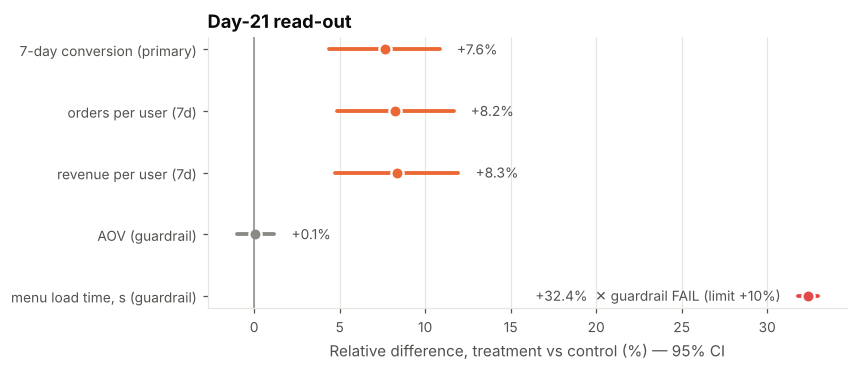

In [8]:
plot_rows = results.drop(index="7-day conversion, CUPED")
fig, ax = plt.subplots(figsize=(7.5, 3.2))
y = np.arange(len(plot_rows))[::-1]
for yi, (name, r) in zip(y, plot_rows.iterrows()):
    failed = name.startswith("menu load")            # guardrail limit: +10%
    color = plots.CRITICAL if failed else (plots.MUTED if "guardrail" in name else plots.TREATMENT)
    ax.plot([r.rel_ci_low * 100, r.rel_ci_high * 100], [yi, yi], color=color, lw=2.5, solid_capstyle="round")
    ax.plot(r.rel_lift * 100, yi, "o", color=color, ms=8, mec="white", mew=1.5)
    label = f"{r.rel_lift:+.1%}" + ("  ✕ guardrail FAIL (limit +10%)" if failed else "")
    ha, x = ("right", r.rel_ci_low * 100 - 1) if failed else ("left", r.rel_ci_high * 100 + 1)
    ax.text(x, yi, label, va="center", ha=ha, fontsize=9, color=plots.TEXT_2)
ax.axvline(0, color=plots.MUTED, lw=1)
ax.set_yticks(y, plot_rows.index)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("Relative difference, treatment vs control (%) — 95% CI")
ax.set_title("Day-21 read-out")
plots.save(fig, "02_readout_forest");

## 4. The headline — and why we are not done

* **Primary metric: +7.6% relative (≈ +0.9 pp), 95% CI +4.4% to +10.9%, p ≈ 2·10⁻⁶.** Bigger than the 5% MDE.
* Orders and revenue per user agree. AOV is flat.
* **Guardrail fails:** menu load time is up 32% on average and 47% at the 75th percentile (limit: +10%).

A team reading only the top line would ship today. Three questions remain, and each
one can flip the decision:

1. **Was this read-out honest?** The live dashboard looked "significant" within days of launch.
   What if someone had acted on it early? Notebook 03 shows what peeking does to the false-positive rate.
2. **Will the effect last?** The primary window is each user's *first* week with a brand-new
   visual design — exactly where novelty lives. Notebook 04.
3. **Is it good for everyone?** The load-time guardrail failure is a clue, and platform was
   pre-registered as a segment. Notebook 05.